[    0.7 s] running OBS ... done in 0.7 s
[    1.4 s] running GCM ... done in 13.3 s
[   14.7 s] running DBCCA ... done in 55.8 s
[   70.5 s] running ISIMIP3BASD ... done in 0.0 s
[   70.5 s] running SRDRN-QDM ... done in 52.6 s
[  123.1 s] drawing Fig05_projection_light_heavy ... 

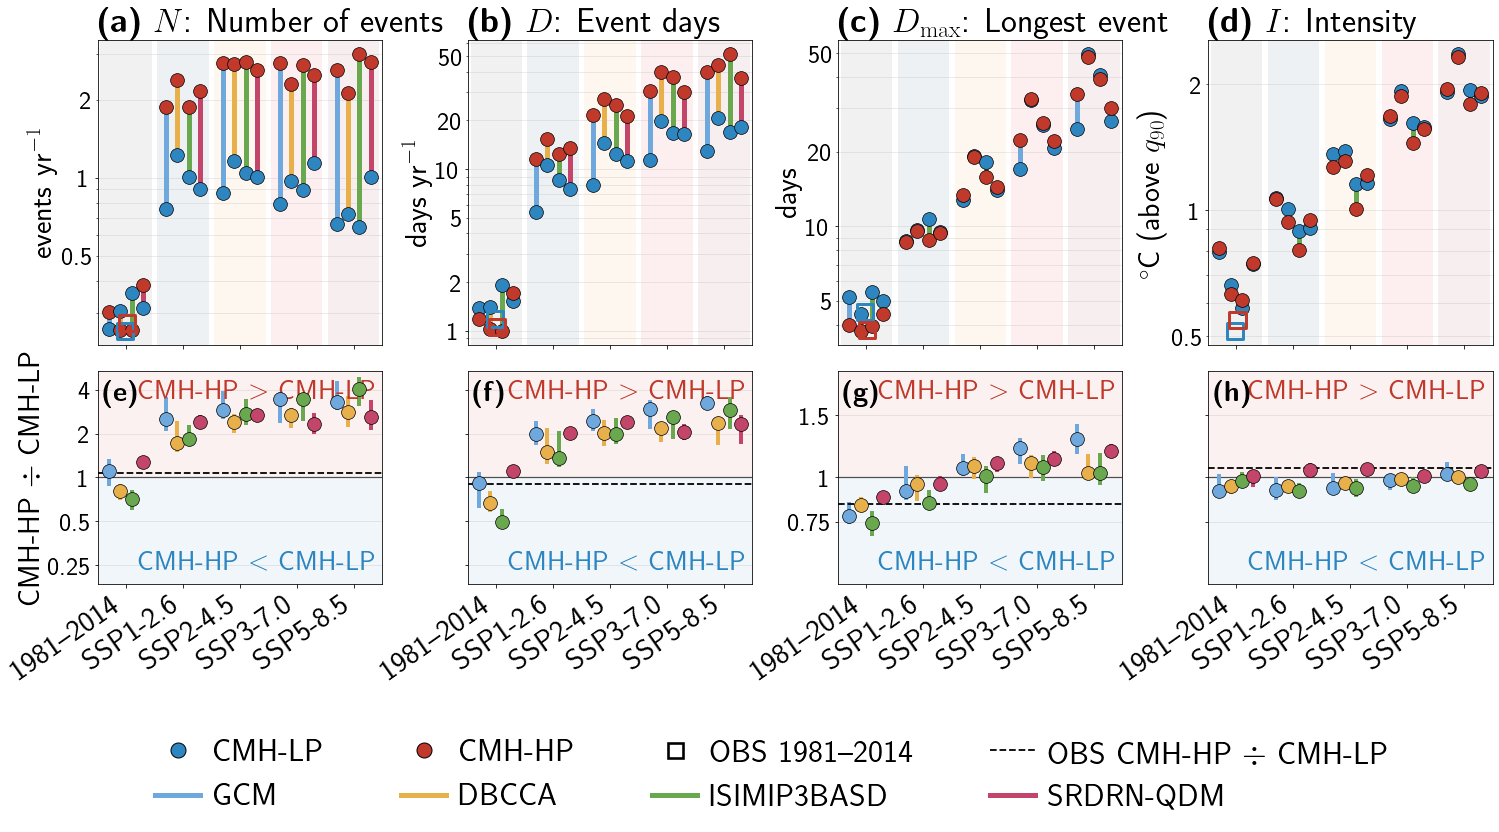

done in 11.0 s
[  134.1 s] TOTAL


In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, gc, time, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt, matplotlib.ticker as mticker, cartopy.io.shapereader as shpr
from concurrent.futures import ThreadPoolExecutor; from matplotlib.lines import Line2D
T0 = time.time(); tk = lambda s_: print(f'[{time.time()-T0:7.1f} s] {s_}', flush=True)
# ---------------- CONFIG ----------------
ROOT = r"D:/G_data"; OUTD = f"{ROOT}/paper-SRDRN/metric-data"; SCF = f"{OUTD}/isimip3basd/series_isimip3basd.npy"
VARS, SSPS, PRODS = ['tasmax', 'hurs', 'pr'], ['ssp126', 'ssp245', 'ssp370', 'ssp585'], ['GCM', 'DBCCA', 'ISIMIP3BASD', 'SRDRN-QDM']
INP = {'ISIMIP3BASD': ROOT + "/out-BASD-ssp-orig/basd_{v}_combined_hist{s}_1981-2100_df4_{m}.nc"}
MODS = ['ACCESS-CM2','ACCESS-ESM1-5','CMCC-CM2-SR5','CMCC-ESM2','CanESM5','EC-Earth3','EC-Earth3-Veg','FGOALS-g3','GFDL-ESM4','INM-CM5-0','IPSL-CM6A-LR','KACE-1-0-G','MIROC6','MPI-ESM1-2-HR','MRI-ESM2-0','NorESM2-MM','TaiESM1']
BASE, FUTW, FULL, MINB, MINF = (1981, 2014), (2067, 2100), (1981, 2100), 20, 20
NM, PQ, MINLEN, L, RBIN, LANDRES, CLS = 5, 90, 3, 3, [1., 5., 20.], '50m', {'light': 1, 'heavy': 3}
BOXES = {'A Mekong': dict(lon=(100.5, 109.5), lat=(9.0, 18.0)), 'B Mindanao': dict(lon=(119.0, 126.0), lat=(5.0, 10.0)), 'C Pen. Malaysia': dict(lon=(98.5, 105.5), lat=(0.3, 8.8)), 'D Java': dict(lon=(105.0, 114.5), lat=(-10.0, -5.0))}
REGS_F = ['Whole land'] + list(BOXES); VNS = [f'{mk}_{c}' for mk in ('HWN', 'HWF', 'HWD', 'HWI') for c in ('light', 'heavy')]
NJ, CH, COMPUTE_MISSING = min(8, os.cpu_count() or 4), 1000, True                # threads | cells per chunk (~1 GB per thread for 1981-2100)
PN = {'DBCCA': 'dbcca', 'ISIMIP3BASD': 'isimip3basd', 'SRDRN-QDM': 'srdrnqdm', 'GCM': 'gcm'}; KO = ('OBS', 'obs', 'hist')
fname = lambda k: os.path.join(OUTD, 'obs', 'obs_metric_hist_MSWX-MSWEP.nc') if k[0] == 'OBS' else os.path.join(OUTD, PN[k[0]], k[2], f'{PN[k[0]]}_metric_{k[2]}_{k[1]}.nc')
SAVE_FIG, FNAME, SAVE_DIR, SUBREG, PRINT_TAB = False, 'Fig05_projection_light_heavy', r"D:/G_data/paper-SRDRN/fig-ver3methods", False, False   # SUBREG: also draw A-D (SI)
USETEX, FS, LEG_Y = True, 30, -.05
MET = [('HWN', r'$N$: Number of events', r'events yr$^{-1}$', True), ('HWF', r'$D$: Event days', r'days yr$^{-1}$', True), ('HWD', r'$D_{\max}$: Longest event', 'days', True), ('HWI', r'$I$: Intensity', r'$^{\circ}$C (above $q_{90}$)', True)]
SCOL = {'ssp126': '#173c66', 'ssp245': '#f69320', 'ssp370': '#e71d25', 'ssp585': '#951b1e'}; SLAB = {'ssp126': 'SSP1-2.6', 'ssp245': 'SSP2-4.5', 'ssp370': 'SSP3-7.0', 'ssp585': 'SSP5-8.5'}
PCOL = {'GCM': '#6FA8DC', 'DBCCA': '#E8B04B', 'ISIMIP3BASD': '#6AA84F', 'SRDRN-QDM': '#C4456A'}; CCOL = {'light': '#2E86C1', 'heavy': '#C0392B'}; CLAB = {'light': 'CMH-LP', 'heavy': 'CMH-HP'}
if USETEX:
    try: plt.rcParams['text.usetex'] = True; _f = plt.figure(); _f.text(.5, .5, r'$T_{w,x}$'); _f.canvas.draw(); plt.close(_f)
    except Exception: USETEX = False; plt.close('all')
# ---------------- utils: I/O + event detection (identical definition) -> regional series directly ----------------
def std_(ds):
    ren = {a: b for a, b in [('latitude', 'lat'), ('longitude', 'lon'), ('Latitude', 'lat'), ('Longitude', 'lon')] if a in ds.dims or a in ds.coords}; ds = ds.rename(ren) if ren else ds
    if ds.lat.size > 1 and float(ds.lat[0]) > float(ds.lat[-1]): ds = ds.sortby('lat')
    if float(ds.lon.min()) < 0: ds = ds.assign_coords(lon=(ds.lon % 360)).sortby('lon')
    return ds
def NL(d):
    cal = d.time.dt.calendar
    if cal in ('noleap', '365_day'): return d
    return d.convert_calendar('noleap', align_on='year', missing=np.nan) if cal == '360_day' else d.convert_calendar('noleap', align_on='date')
def fxp(da, v):
    u = str(da.attrs.get('units', '')).lower().replace(' ', ''); s = da.isel(time=slice(0, 366)).values
    if v == 'tasmax' and (u in ('k', 'kelvin') or np.nanmin(s) > 100): return 1., -273.15
    if v == 'pr' and (u in ('kgm-2s-1', 'kg/m2/s') or 0 < np.nanmax(s) < 0.01): return 86400., 0.
    if v == 'hurs' and np.nanmax(s) <= 1.5: return 100., 0.
    return 1., 0.
def landgrid(la, lo):
    import shapely.geometry as sgeom; from shapely.prepared import prep; from shapely.ops import unary_union
    pl = prep(unary_union(list(shpr.Reader(shpr.natural_earth(resolution=LANDRES, category='physical', name='land')).geometries()))); x = ((np.asarray(lo)+180.) % 360.) - 180.; X, Y = np.meshgrid(x, np.asarray(la))
    return np.fromiter((pl.contains(sgeom.Point(a, b)) for a, b in zip(X.ravel(), Y.ravel())), bool, X.size).reshape(X.shape)
LMK = globals().get('LMK', {})
def lm(la, lo):
    k = (la.size, lo.size, round(float(la[0]), 3), round(float(lo[0]), 3))
    if k not in LMK: LMK[k] = landgrid(la, lo)
    return LMK[k]
def stull(Tc, R):
    R = np.clip(R, 5., 99.5); return (Tc*np.arctan(0.151977*np.sqrt(R+8.313659)) + np.arctan(Tc+R) - np.arctan(R-1.676331) + 0.00391838*R**1.5*np.arctan(0.023101*R) - 4.686035).astype('f4')
def load3p(fs):                                                                  # 1981-2100, land cells only, read in 10-yr blocks
    X, K, la, lo, VI = {}, {}, None, None, None
    for v in VARS:
        with xr.open_dataset(fs[v], use_cftime=True) as d0:
            d = std_(d0); vn = v if v in d.data_vars else next((x for x in (['rh', 'relative_humidity'] if v == 'hurs' else []) if x in d.data_vars), next(x for x in d.data_vars if d[x].ndim == 3))
            da = NL(d[vn].sel(time=slice(str(FULL[0]), str(FULL[1])))).transpose('time', 'lat', 'lon'); sc, of = fxp(da, v)
            if la is None: la, lo = da.lat.values.astype('f8'), da.lon.values.astype('f8'); VI = np.flatnonzero(lm(la, lo).ravel())
            elif not (da.lat.size == la.size and da.lon.size == lo.size and np.allclose(da.lat, la, atol=1e-3) and np.allclose(da.lon, lo, atol=1e-3)): da = da.reindex(lat=la, lon=lo, method='nearest')
            nt = da.sizes['time']; A = np.empty((VI.size, nt), 'f4')
            for i0 in range(0, nt, 3650): A[:, i0:i0+3650] = (da.isel(time=slice(i0, i0+3650)).values.astype('f4').reshape(-1, la.size*lo.size)[:, VI]*sc + of).T
            X[v] = A; K[v] = pd.MultiIndex.from_arrays([da.time.dt.year.values, da.time.dt.dayofyear.values])
            if v == 'tasmax': YR, MO = da.time.dt.year.values.astype('i4'), da.time.dt.month.values.astype('i4')
        gc.collect()
    com = K['tasmax'].intersection(K['hurs']).intersection(K['pr'])
    for v in VARS:
        if len(com) < K[v].size: X[v] = X[v][:, np.flatnonzero(K[v].isin(com))]
    it = np.flatnonzero(K['tasmax'].isin(com)); YR, MO = YR[it], MO[it]; fin = np.ones(VI.size, bool)
    for v in VARS: fin &= np.isfinite(X[v]).mean(1) >= .9
    for v in VARS: X[v] = np.ascontiguousarray(X[v][fin])
    VI = VI[fin]; return X, la[VI // lo.size], lo[VI % lo.size], YR, MO
def pchunk(tx, rh, PR, M0, B, yi, NY, la, lo):                                    # season + q90 from own 1981-2014 -> regional (cos-lat) sums of annual metrics
    TW = stull(tx, rh); n, T = TW.shape; r_ = np.arange(n)
    MTW = np.stack([np.nanmean(TW[:, B & (M0 == m)], 1) for m in range(12)], 1); cs_ = np.concatenate([MTW, MTW[:, :NM-1]], 1); ons = np.nanargmax(np.stack([cs_[:, i:i+NM].mean(1) for i in range(12)], 1), 1)
    INS = np.zeros((n, 12), bool); INS[r_[:, None], (ons[:, None] + np.arange(NM)) % 12] = True; SD = INS[:, M0]
    V = SD & B[None, :] & np.isfinite(TW); kq = V.sum(1); A = np.sort(np.where(V, TW, np.inf), 1); del V
    pos = (np.maximum(kq, 1) - 1)*PQ/100.; lo_ = np.floor(pos).astype(int); hi_ = np.minimum(lo_ + 1, np.maximum(kq - 1, 0))
    with np.errstate(invalid='ignore'): q = (A[r_, lo_] + (A[r_, hi_] - A[r_, lo_])*(pos - lo_)).astype('f4')
    q[kq == 0] = np.nan; del A
    dd = np.diff(np.pad(((TW > q[:, None]) & SD).astype(np.int8), ((0, 0), (1, 1))), axis=1); c, s = np.nonzero(dd == 1); _, e = np.nonzero(dd == -1); del dd, SD
    du = e - s; k = du >= MINLEN; c, s, du = c[k], s[k], du[k]; mx = np.full(c.size, -1., 'f4')
    for kk in range(-L, L+1): t = s + kk; ok = (t >= 0) & (t < T); mx[ok] = np.fmax(mx[ok], PR[c[ok], t[ok]])
    cls = np.digitize(mx, RBIN).astype('i1'); cls[mx < 0] = -1
    CS = np.cumsum(np.nan_to_num(TW - q[:, None]), axis=1, dtype='f8'); es = CS[c, s + du - 1] - np.where(s > 0, CS[c, np.maximum(s - 1, 0)], 0.); del CS, TW
    ey = yi[s]; w = np.cos(np.radians(la)); okc = np.isfinite(q)
    RC = [okc] + [okc & (lo >= bb['lon'][0]) & (lo <= bb['lon'][1]) & (la >= bb['lat'][0]) & (la <= bb['lat'][1]) for bb in BOXES.values()]
    NUM = np.zeros((len(VNS), len(REGS_F), NY)); DEN = np.zeros_like(NUM)
    for cn, cv in CLS.items():
        m = cls == cv; idx = ey[m]*n + c[m]; N = np.bincount(idx, minlength=NY*n).reshape(NY, n).astype('f4'); F = np.bincount(idx, du[m], NY*n).reshape(NY, n).astype('f4')
        D = np.zeros(NY*n, 'f4'); np.maximum.at(D, idx, du[m].astype('f4')); D = D.reshape(NY, n); D[N == 0] = np.nan
        with np.errstate(invalid='ignore', divide='ignore'): I = (np.bincount(idx, es[m], NY*n).reshape(NY, n)/np.where(F > 0, F, np.nan)).astype('f4')
        for mk, Z in zip(('HWN', 'HWF', 'HWD', 'HWI'), (N, F, D, I)):
            iv = VNS.index(f'{mk}_{cn}'); fz = np.isfinite(Z); Z0 = np.where(fz, Z, 0.).astype('f8'); fz = fz.astype('f8')
            for ir, rc in enumerate(RC): ww = w*rc; NUM[iv, ir] = Z0 @ ww; DEN[iv, ir] = fz @ ww
    return NUM, DEN
def series_in(fs):
    X, la, lo, YR, MO = load3p(fs); M0 = MO - 1; B = (YR >= BASE[0]) & (YR <= BASE[1]); YRU = np.unique(YR); yi = np.searchsorted(YRU, YR); n = X['tasmax'].shape[0]
    job = lambda ab: pchunk(X['tasmax'][ab[0]:ab[1]], X['hurs'][ab[0]:ab[1]], X['pr'][ab[0]:ab[1]], M0, B, yi, YRU.size, la[ab[0]:ab[1]], lo[ab[0]:ab[1]])
    with ThreadPoolExecutor(NJ) as ex: R = list(ex.map(job, [(i, min(i + CH, n)) for i in range(0, n, CH)]))
    NUM, DEN = sum(r[0] for r in R), sum(r[1] for r in R); del X, R; gc.collect(); o = {'years': YRU.astype(int)}
    for iv, v in enumerate(VNS):
        for ir, reg in enumerate(REGS_F): o[(v, reg)] = np.where(DEN[iv, ir] > 0, NUM[iv, ir]/np.maximum(DEN[iv, ir], 1e-12), np.nan)
    return o
def rser(f):                                                                     # regional series from a metric file (dataset's own land cells)
    with xr.open_dataset(f, decode_times=False) as ds:
        land = np.isfinite(ds['q90'].values); LA, LO = np.meshgrid(ds.lat.values, ds.lon.values, indexing='ij'); w = np.cos(np.radians(LA))
        M = {'Whole land': land, **{b: land & (LO >= bb['lon'][0]) & (LO <= bb['lon'][1]) & (LA >= bb['lat'][0]) & (LA <= bb['lat'][1]) for b, bb in BOXES.items()}}; o = {'years': np.asarray(ds.time.values).astype(int)}
        for v in VNS:
            X = np.asarray(ds[v].values, 'f8')
            for reg, m in M.items(): num = np.nansum(X[:, m]*w[m], 1); den = np.nansum(np.isfinite(X[:, m])*w[m], 1); o[(v, reg)] = np.where(den > 0, num/np.maximum(den, 1e-12), np.nan)
        return o
ok_series = lambda o: isinstance(o, dict) and np.asarray(o.get(('HWD_light', 'Whole land'), [np.nan])).dtype.kind == 'f' and np.isfinite(o[('HWD_light', 'Whole land')]).any()
# ---------------- PRS: RAM -> ISIMIP3BASD series cache -> metric files -> compute missing ----------------
PRS, PRS_MISS = globals().get('PRS', {}), globals().get('PRS_MISS', set()); ERR = {}
if os.path.exists(SCF):
    for k, o in np.load(SCF, allow_pickle=True).item().items():
        if isinstance(k, tuple) and len(k) == 3 and not (k in PRS and ok_series(PRS[k])) and ok_series(o): PRS[k] = o
for p in ['OBS'] + PRODS:
    keys = [KO] if p == 'OBS' else [(p, m, s_) for s_ in SSPS for m in MODS]; todo = [k for k in keys if not (k in PRS and ok_series(PRS[k])) and k not in PRS_MISS]
    if not todo: continue
    t_ = time.time(); print(f'[{t_-T0:7.1f} s] running {p} ...', end=' ', flush=True)
    for k in todo:
        try:
            if os.path.exists(fname(k)): PRS[k] = rser(fname(k)); continue
            fs = {v: INP[k[0]].format(v=v, s=k[2], m=k[1]) for v in VARS} if k[0] in INP else {}
            if COMPUTE_MISSING and fs and all(os.path.exists(f) for f in fs.values()): PRS[k] = series_in(fs); gc.collect()
            else: PRS_MISS.add(k)
        except Exception as e: ERR[k] = f'{type(e).__name__}: {e}'
    print(f'done in {time.time()-t_:.1f} s', flush=True)
OKM = {(p, s_): [m for m in MODS if (p, m, s_) in PRS] for p in PRODS for s_ in SSPS}
# ---------------- values: light, heavy, heavy/light per model | baseline + each SSP in FUTW ----------------
def pvr(o, v, r, win, nmin):
    y = np.asarray(o['years']); x = np.asarray(o[(v, r)], 'f8')[(y >= win[0]) & (y <= win[1])]; return float(np.nanmean(x)) if np.isfinite(x).sum() >= nmin else np.nan
POS = [(BASE, 'hist')] + [(FUTW, s_) for s_ in SSPS]; OFFP = dict(zip(PRODS, np.linspace(-.3, .3, len(PRODS)))); nC = len(MET)
def valr(r):
    V_ = {}
    for key, *_ in MET:
        for p in PRODS:
            sref = next((s_ for s_ in SSPS if OKM[(p, s_)]), None)               # baseline from the hist part of the first available SSP run
            if sref is None: continue
            for x_, (win, s_) in enumerate(POS):
                sx = sref if s_ == 'hist' else s_; ms = OKM[(p, sx)]; nmin = MINB if s_ == 'hist' else MINF
                if not ms: continue
                L_ = np.array([pvr(PRS[(p, m, sx)], f'{key}_light', r, win, nmin) for m in ms]); H_ = np.array([pvr(PRS[(p, m, sx)], f'{key}_heavy', r, win, nmin) for m in ms])
                with np.errstate(invalid='ignore', divide='ignore'): V_[(key, p, x_)] = (L_, H_, np.where(L_ > 0, H_/L_, np.nan))
    return V_
# ---------------- figure ----------------
plt.rcParams.update({'text.usetex': USETEX, 'font.size': FS-2, 'axes.titlesize': FS-4, 'axes.labelsize': FS, 'xtick.labelsize': FS-4, 'ytick.labelsize': FS-4, 'legend.fontsize': FS-4})
bf = (lambda s_: r'\textbf{' + s_ + '}') if USETEX else (lambda s_: s_); DIV = r'$\div$' if USETEX else '/'; DASH = '--' if USETEX else '-'; LET = 'abcdefghijklmnopqrstuvwxyz'
GT, LT = (r'$>$', r'$<$') if USETEX else ('>', '<'); XL = [f'{BASE[0]}{DASH}{BASE[1]}'] + [SLAB[s_] for s_ in SSPS]
LOGF = mticker.FuncFormatter(lambda v, _: f'{v:g}' if v > 0 and round(v/10**np.floor(np.log10(v)), 6) in (1, 2, 5) else '')
def rowmajor(H, nc): nr = -(-len(H)//nc); return [H[i*nc + j] for j in range(nc) for i in range(nr) if i*nc + j < len(H)]
def draw_mag(VALr, r, fn, title=None, grp=(([0, 1], None), ([2, 3], 2))):
    fig = plt.figure(figsize=(25, 10)); gs = fig.add_gridspec(2, nC, height_ratios=[1, .7], hspace=.1, wspace=.3); B = []; rows = []
    for j, (key, ttl, unit, lg) in enumerate(MET):
        a = fig.add_subplot(gs[0, j]); b = fig.add_subplot(gs[1, j], sharex=a); B.append(b)
        for x_ in range(len(POS)):
            a.axvspan(x_ - .45, x_ + .45, color=('0.88' if x_ == 0 else SCOL[POS[x_][1]]), alpha=(.45 if x_ == 0 else .07), lw=0, zorder=0)
            for p in PRODS:
                if (key, p, x_) not in VALr: continue
                L_, H_, R_ = VALr[(key, p, x_)]
                if not (np.isfinite(L_).any() and np.isfinite(H_).any()): continue
                ml, mh = np.nanmedian(L_), np.nanmedian(H_); xx = x_ + OFFP[p]
                a.plot([xx, xx], [ml, mh], color=PCOL[p], lw=5, solid_capstyle='round', zorder=3)
                a.scatter(xx, ml, s=190, color=CCOL['light'], ec='k', lw=.7, zorder=5); a.scatter(xx, mh, s=190, color=CCOL['heavy'], ec='k', lw=.7, zorder=5)
                r_ = R_[np.isfinite(R_) & (R_ > 0)]
                if r_.size:
                    q1, q2, q3 = np.percentile(r_, [25, 50, 75]); b.vlines(xx, q1, q3, color=PCOL[p], lw=4, zorder=3); b.scatter(xx, q2, s=190, color=PCOL[p], ec='k', lw=.7, zorder=5)
                    rows.append(dict(region=r, metric=key, period=XL[x_], product=p, n=int(r_.size), light=round(ml, 2), heavy=round(mh, 2), heavy_over_light=round(q2, 2)))
        if KO in PRS:
            ol, oh = pvr(PRS[KO], f'{key}_light', r, BASE, MINB), pvr(PRS[KO], f'{key}_heavy', r, BASE, MINB)
            a.scatter([-.02, .02], [ol, oh], s=260, marker='s', facecolor='none', ec=[CCOL['light'], CCOL['heavy']], lw=3, zorder=6)
            if ol > 0 and oh > 0: b.axhline(oh/ol, color='k', lw=1.8, ls='--', zorder=4)
        b.set_yscale('log'); b.axhline(1, color='0.3', lw=1.2, zorder=2)
        b.text(.98, .96, f'{CLAB["heavy"]} {GT} {CLAB["light"]}', transform=b.transAxes, ha='right', va='top', color=CCOL['heavy'], fontsize=FS-2)
        b.text(.98, .04, f'{CLAB["heavy"]} {LT} {CLAB["light"]}', transform=b.transAxes, ha='right', va='bottom', color=CCOL['light'], fontsize=FS-2)
        if lg: a.set_yscale('log'); a.yaxis.set_major_formatter(LOGF); a.yaxis.set_minor_formatter(LOGF)
        for ax_ in (a, b): ax_.grid(alpha=.3, axis='y', which='both')
        a.set_xlim(-.5, len(POS) - .5); a.tick_params(labelbottom=False); b.set_xticks(range(len(POS))); b.set_xticklabels(XL, rotation=35, ha='right', fontsize=FS)
        a.set_title(bf(f'({LET[j]})') + f' {ttl}', loc='left', fontsize=FS+4); a.set_ylabel(unit); b.text(.02, .96, bf(f'({LET[nC + j]})'), transform=b.transAxes, va='top', fontsize=FS-2)
        if j == 0: b.set_ylabel(f'{CLAB["heavy"]} {DIV} {CLAB["light"]}')
    for cols, MF in grp:                                                         # symmetric limits around 1 on the log axis
        cols = [c for c in cols if c < len(B)]; M = MF if MF else max([1.25] + [max(1/B[c].get_ylim()[0], B[c].get_ylim()[1]) for c in cols])
        tks = [.25, .5, 1, 2, 4] if M >= 2.5 else ([.75, 1, 1.5] if M >= 1.6 else [.8, 1, 1.25]); tks = [t for t in tks if 1/M <= t <= M]
        for i, c in enumerate(cols):
            b = B[c]; b.set_ylim(1/M, M); b.axhspan(1, M, color=CCOL['heavy'], alpha=.07, lw=0, zorder=0); b.axhspan(1/M, 1, color=CCOL['light'], alpha=.07, lw=0, zorder=0)
            b.yaxis.set_major_locator(mticker.FixedLocator(tks)); b.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}')); b.yaxis.set_minor_locator(mticker.NullLocator())
            if i: b.tick_params(labelleft=False)
    R1 = [Line2D([], [], marker='o', ls='', ms=15, color=CCOL[c], mec='k', label=CLAB[c]) for c in ['light', 'heavy']] + \
         [Line2D([], [], marker='s', ls='', ms=15, mfc='none', mec='k', mew=2.6, label=f'OBS {BASE[0]}{DASH}{BASE[1]}'), Line2D([], [], color='k', ls='--', lw=1.8, label=f'OBS {CLAB["heavy"]} {DIV} {CLAB["light"]}')]
    R2 = [Line2D([], [], color=PCOL[p], lw=5, label=p) for p in PRODS]
    fig.legend(handles=rowmajor(R1 + R2, 4), loc='upper center', ncol=4, frameon=False, bbox_to_anchor=(.5, LEG_Y), fontsize=FS+2, handletextpad=.4, handlelength=1.4, columnspacing=2.4, labelspacing=.5)
    if title: fig.suptitle(bf(title), fontsize=FS+10, y=1.03)
    if SAVE_FIG: os.makedirs(SAVE_DIR, exist_ok=True); fig.savefig(os.path.join(SAVE_DIR, f'{fn}.pdf'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig); return rows
t_ = time.time(); print(f'[{t_-T0:7.1f} s] drawing {FNAME} ...', end=' ', flush=True); TBL = pd.DataFrame(draw_mag(valr('Whole land'), 'Whole land', FNAME)); print(f'done in {time.time()-t_:.1f} s', flush=True)
if SUBREG:
    for r in BOXES:
        t_ = time.time(); print(f'[{t_-T0:7.1f} s] drawing {r} ...', end=' ', flush=True)
        draw_mag(valr(r), r, f'{FNAME}_{r.split()[0]}', title=r.split()[0] + '. ' + ' '.join(r.split()[1:]), grp=(([0, 1], None), ([2, 3], None))); print(f'done in {time.time()-t_:.1f} s', flush=True)
if PRINT_TAB: print(TBL.pivot_table(index=['metric', 'period'], columns='product', values='heavy_over_light').reindex(columns=PRODS).round(2).to_string())
tk('TOTAL')

[    1.2 s] computing amplification ... done in 2.2 s
[    3.4 s] drawing Fig06_signal_preservation ... 

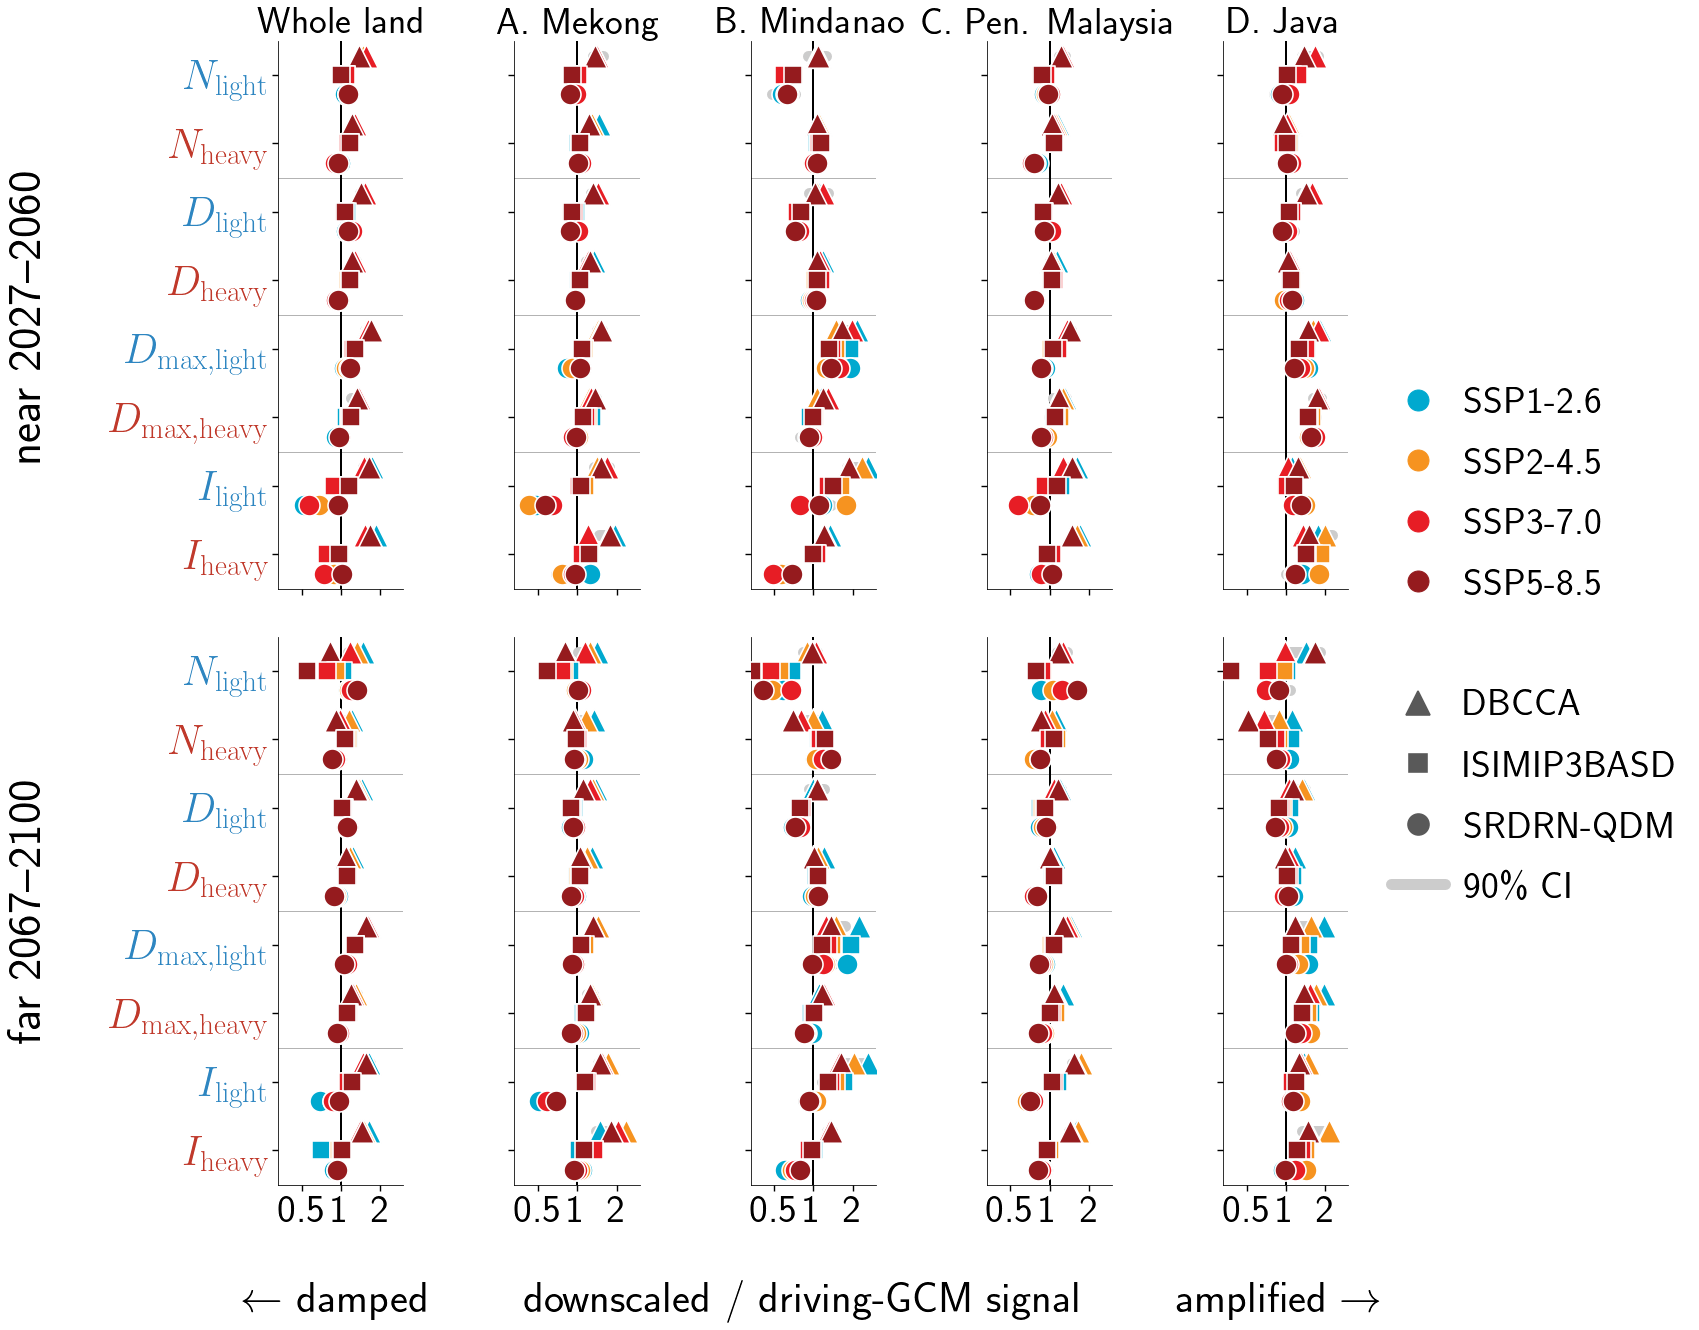

done in 14.2 s
[   17.7 s] TOTAL


In [2]:
import warnings; warnings.filterwarnings('ignore')
import os, gc, time, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt, cartopy.io.shapereader as shpr
from concurrent.futures import ThreadPoolExecutor; from matplotlib.lines import Line2D
T0 = time.time(); tk = lambda s_: print(f'[{time.time()-T0:7.1f} s] {s_}', flush=True)
# ---------------- CONFIG ----------------
ROOT = r"D:/G_data"; OUTD = f"{ROOT}/paper-SRDRN/metric-data"; SCF = f"{OUTD}/isimip3basd/series_isimip3basd.npy"
VARS, SSPS, PRODS, DSP = ['tasmax', 'hurs', 'pr'], ['ssp126', 'ssp245', 'ssp370', 'ssp585'], ['GCM', 'DBCCA', 'ISIMIP3BASD', 'SRDRN-QDM'], ['DBCCA', 'ISIMIP3BASD', 'SRDRN-QDM']
INP = {'ISIMIP3BASD': ROOT + "/out-BASD-ssp-orig/basd_{v}_combined_hist{s}_1981-2100_df4_{m}.nc"}
MODS = ['ACCESS-CM2','ACCESS-ESM1-5','CMCC-CM2-SR5','CMCC-ESM2','CanESM5','EC-Earth3','EC-Earth3-Veg','FGOALS-g3','GFDL-ESM4','INM-CM5-0','IPSL-CM6A-LR','KACE-1-0-G','MIROC6','MPI-ESM1-2-HR','MRI-ESM2-0','NorESM2-MM','TaiESM1']
BASE, FULL = (1981, 2014), (1981, 2100); NM, PQ, MINLEN, L, RBIN, LANDRES, CLS = 5, 90, 3, 3, [1., 5., 20.], '50m', {'light': 1, 'heavy': 3}
BOXES = {'A Mekong': dict(lon=(100.5, 109.5), lat=(9.0, 18.0)), 'B Mindanao': dict(lon=(119.0, 126.0), lat=(5.0, 10.0)), 'C Pen. Malaysia': dict(lon=(98.5, 105.5), lat=(0.3, 8.8)), 'D Java': dict(lon=(105.0, 114.5), lat=(-10.0, -5.0))}
REGS_F = ['Whole land'] + list(BOXES); VNS = [f'{mk}_{c}' for mk in ('HWN', 'HWF', 'HWD', 'HWI') for c in ('light', 'heavy')]
NJ, CH, COMPUTE_MISSING = min(8, os.cpu_count() or 4), 1000, True
PN = {'DBCCA': 'dbcca', 'ISIMIP3BASD': 'isimip3basd', 'SRDRN-QDM': 'srdrnqdm', 'GCM': 'gcm'}
fname = lambda k: os.path.join(OUTD, PN[k[0]], k[2], f'{PN[k[0]]}_metric_{k[2]}_{k[1]}.nc')
SAVE_FIG, FNAME, SAVE_DIR, PRINT_TAB = False, 'Fig06_signal_preservation', r"D:/G_data/paper-SRDRN/fig-ver3methods", False
USETEX, FS, NBOOT, XLIM, MINPAIR, FIGSZ = True, 42, 1000, (.33, 3.), 4, (24, 19)
DOT, MSC, BARW, BARC, EDGE = 15, 1.4, 11, '0.80', 'w'                             # reference marker size (pt) | scale | CI bar width / colour | marker edge
PER, GMIN, MINY = {'near': (2027, 2060), 'far': (2067, 2100)}, {'ratio': .05, 'abs': .05}, {'HWN': 25, 'HWF': 25, 'HWD': 10, 'HWI': 10}
MET6 = [('HWN', 'N', 'ratio'), ('HWF', 'D', 'ratio'), ('HWD', r'D_{\max', 'ratio'), ('HWI', 'I', 'abs')]; ROWS = [(key, sym, mode, cn) for key, sym, mode in MET6 for cn in ('light', 'heavy')]
YLAB = lambda sym, cn: (f'${sym},\\mathrm{{{cn}}}}}$' if sym.endswith('max') else f'${sym}_{{\\mathrm{{{cn}}}}}$')
SLAB = {'ssp126': 'SSP1-2.6', 'ssp245': 'SSP2-4.5', 'ssp370': 'SSP3-7.0', 'ssp585': 'SSP5-8.5'}; SCOL6 = {'ssp126': '#00A9CF', 'ssp245': '#f69320', 'ssp370': '#e71d25', 'ssp585': '#951b1e'}
CCOL = {'light': '#2E86C1', 'heavy': '#C0392B'}; MK = {'DBCCA': ('^', 1.12), 'ISIMIP3BASD': ('s', .86), 'SRDRN-QDM': ('o', 1.)}
RLAB = {r: (r if r == 'Whole land' else r.split()[0] + '. ' + ' '.join(r.split()[1:])) for r in REGS_F}
if USETEX:
    try: plt.rcParams['text.usetex'] = True; _f = plt.figure(); _f.text(.5, .5, r'$T_{w,x}$'); _f.canvas.draw(); plt.close(_f)
    except Exception: USETEX = False; plt.close('all')
# ---------------- utils (same as the Fig 5 cell) ----------------
def std_(ds):
    ren = {a: b for a, b in [('latitude', 'lat'), ('longitude', 'lon'), ('Latitude', 'lat'), ('Longitude', 'lon')] if a in ds.dims or a in ds.coords}; ds = ds.rename(ren) if ren else ds
    if ds.lat.size > 1 and float(ds.lat[0]) > float(ds.lat[-1]): ds = ds.sortby('lat')
    if float(ds.lon.min()) < 0: ds = ds.assign_coords(lon=(ds.lon % 360)).sortby('lon')
    return ds
def NL(d):
    cal = d.time.dt.calendar
    if cal in ('noleap', '365_day'): return d
    return d.convert_calendar('noleap', align_on='year', missing=np.nan) if cal == '360_day' else d.convert_calendar('noleap', align_on='date')
def fxp(da, v):
    u = str(da.attrs.get('units', '')).lower().replace(' ', ''); s = da.isel(time=slice(0, 366)).values
    if v == 'tasmax' and (u in ('k', 'kelvin') or np.nanmin(s) > 100): return 1., -273.15
    if v == 'pr' and (u in ('kgm-2s-1', 'kg/m2/s') or 0 < np.nanmax(s) < 0.01): return 86400., 0.
    if v == 'hurs' and np.nanmax(s) <= 1.5: return 100., 0.
    return 1., 0.
def landgrid(la, lo):
    import shapely.geometry as sgeom; from shapely.prepared import prep; from shapely.ops import unary_union
    pl = prep(unary_union(list(shpr.Reader(shpr.natural_earth(resolution=LANDRES, category='physical', name='land')).geometries()))); x = ((np.asarray(lo)+180.) % 360.) - 180.; X, Y = np.meshgrid(x, np.asarray(la))
    return np.fromiter((pl.contains(sgeom.Point(a, b)) for a, b in zip(X.ravel(), Y.ravel())), bool, X.size).reshape(X.shape)
LMK = globals().get('LMK', {})
def lm(la, lo):
    k = (la.size, lo.size, round(float(la[0]), 3), round(float(lo[0]), 3))
    if k not in LMK: LMK[k] = landgrid(la, lo)
    return LMK[k]
def stull(Tc, R):
    R = np.clip(R, 5., 99.5); return (Tc*np.arctan(0.151977*np.sqrt(R+8.313659)) + np.arctan(Tc+R) - np.arctan(R-1.676331) + 0.00391838*R**1.5*np.arctan(0.023101*R) - 4.686035).astype('f4')
def load3p(fs):
    X, K, la, lo, VI = {}, {}, None, None, None
    for v in VARS:
        with xr.open_dataset(fs[v], use_cftime=True) as d0:
            d = std_(d0); vn = v if v in d.data_vars else next((x for x in (['rh', 'relative_humidity'] if v == 'hurs' else []) if x in d.data_vars), next(x for x in d.data_vars if d[x].ndim == 3))
            da = NL(d[vn].sel(time=slice(str(FULL[0]), str(FULL[1])))).transpose('time', 'lat', 'lon'); sc, of = fxp(da, v)
            if la is None: la, lo = da.lat.values.astype('f8'), da.lon.values.astype('f8'); VI = np.flatnonzero(lm(la, lo).ravel())
            elif not (da.lat.size == la.size and da.lon.size == lo.size and np.allclose(da.lat, la, atol=1e-3) and np.allclose(da.lon, lo, atol=1e-3)): da = da.reindex(lat=la, lon=lo, method='nearest')
            nt = da.sizes['time']; A = np.empty((VI.size, nt), 'f4')
            for i0 in range(0, nt, 3650): A[:, i0:i0+3650] = (da.isel(time=slice(i0, i0+3650)).values.astype('f4').reshape(-1, la.size*lo.size)[:, VI]*sc + of).T
            X[v] = A; K[v] = pd.MultiIndex.from_arrays([da.time.dt.year.values, da.time.dt.dayofyear.values])
            if v == 'tasmax': YR, MO = da.time.dt.year.values.astype('i4'), da.time.dt.month.values.astype('i4')
        gc.collect()
    com = K['tasmax'].intersection(K['hurs']).intersection(K['pr'])
    for v in VARS:
        if len(com) < K[v].size: X[v] = X[v][:, np.flatnonzero(K[v].isin(com))]
    it = np.flatnonzero(K['tasmax'].isin(com)); YR, MO = YR[it], MO[it]; fin = np.ones(VI.size, bool)
    for v in VARS: fin &= np.isfinite(X[v]).mean(1) >= .9
    for v in VARS: X[v] = np.ascontiguousarray(X[v][fin])
    VI = VI[fin]; return X, la[VI // lo.size], lo[VI % lo.size], YR, MO
def pchunk(tx, rh, PR, M0, B, yi, NY, la, lo):
    TW = stull(tx, rh); n, T = TW.shape; r_ = np.arange(n)
    MTW = np.stack([np.nanmean(TW[:, B & (M0 == m)], 1) for m in range(12)], 1); cs_ = np.concatenate([MTW, MTW[:, :NM-1]], 1); ons = np.nanargmax(np.stack([cs_[:, i:i+NM].mean(1) for i in range(12)], 1), 1)
    INS = np.zeros((n, 12), bool); INS[r_[:, None], (ons[:, None] + np.arange(NM)) % 12] = True; SD = INS[:, M0]
    V = SD & B[None, :] & np.isfinite(TW); kq = V.sum(1); A = np.sort(np.where(V, TW, np.inf), 1); del V
    pos = (np.maximum(kq, 1) - 1)*PQ/100.; lo_ = np.floor(pos).astype(int); hi_ = np.minimum(lo_ + 1, np.maximum(kq - 1, 0))
    with np.errstate(invalid='ignore'): q = (A[r_, lo_] + (A[r_, hi_] - A[r_, lo_])*(pos - lo_)).astype('f4')
    q[kq == 0] = np.nan; del A
    dd = np.diff(np.pad(((TW > q[:, None]) & SD).astype(np.int8), ((0, 0), (1, 1))), axis=1); c, s = np.nonzero(dd == 1); _, e = np.nonzero(dd == -1); del dd, SD
    du = e - s; k = du >= MINLEN; c, s, du = c[k], s[k], du[k]; mx = np.full(c.size, -1., 'f4')
    for kk in range(-L, L+1): t = s + kk; ok = (t >= 0) & (t < T); mx[ok] = np.fmax(mx[ok], PR[c[ok], t[ok]])
    cls = np.digitize(mx, RBIN).astype('i1'); cls[mx < 0] = -1
    CS = np.cumsum(np.nan_to_num(TW - q[:, None]), axis=1, dtype='f8'); es = CS[c, s + du - 1] - np.where(s > 0, CS[c, np.maximum(s - 1, 0)], 0.); del CS, TW
    ey = yi[s]; w = np.cos(np.radians(la)); okc = np.isfinite(q)
    RC = [okc] + [okc & (lo >= bb['lon'][0]) & (lo <= bb['lon'][1]) & (la >= bb['lat'][0]) & (la <= bb['lat'][1]) for bb in BOXES.values()]
    NUM = np.zeros((len(VNS), len(REGS_F), NY)); DEN = np.zeros_like(NUM)
    for cn, cv in CLS.items():
        m = cls == cv; idx = ey[m]*n + c[m]; N = np.bincount(idx, minlength=NY*n).reshape(NY, n).astype('f4'); F = np.bincount(idx, du[m], NY*n).reshape(NY, n).astype('f4')
        D = np.zeros(NY*n, 'f4'); np.maximum.at(D, idx, du[m].astype('f4')); D = D.reshape(NY, n); D[N == 0] = np.nan
        with np.errstate(invalid='ignore', divide='ignore'): I = (np.bincount(idx, es[m], NY*n).reshape(NY, n)/np.where(F > 0, F, np.nan)).astype('f4')
        for mk, Z in zip(('HWN', 'HWF', 'HWD', 'HWI'), (N, F, D, I)):
            iv = VNS.index(f'{mk}_{cn}'); fz = np.isfinite(Z); Z0 = np.where(fz, Z, 0.).astype('f8'); fz = fz.astype('f8')
            for ir, rc in enumerate(RC): ww = w*rc; NUM[iv, ir] = Z0 @ ww; DEN[iv, ir] = fz @ ww
    return NUM, DEN
def series_in(fs):
    X, la, lo, YR, MO = load3p(fs); M0 = MO - 1; B = (YR >= BASE[0]) & (YR <= BASE[1]); YRU = np.unique(YR); yi = np.searchsorted(YRU, YR); n = X['tasmax'].shape[0]
    job = lambda ab: pchunk(X['tasmax'][ab[0]:ab[1]], X['hurs'][ab[0]:ab[1]], X['pr'][ab[0]:ab[1]], M0, B, yi, YRU.size, la[ab[0]:ab[1]], lo[ab[0]:ab[1]])
    with ThreadPoolExecutor(NJ) as ex: R = list(ex.map(job, [(i, min(i + CH, n)) for i in range(0, n, CH)]))
    NUM, DEN = sum(r[0] for r in R), sum(r[1] for r in R); del X, R; gc.collect(); o = {'years': YRU.astype(int)}
    for iv, v in enumerate(VNS):
        for ir, reg in enumerate(REGS_F): o[(v, reg)] = np.where(DEN[iv, ir] > 0, NUM[iv, ir]/np.maximum(DEN[iv, ir], 1e-12), np.nan)
    return o
def rser(f):
    with xr.open_dataset(f, decode_times=False) as ds:
        land = np.isfinite(ds['q90'].values); LA, LO = np.meshgrid(ds.lat.values, ds.lon.values, indexing='ij'); w = np.cos(np.radians(LA))
        M = {'Whole land': land, **{b: land & (LO >= bb['lon'][0]) & (LO <= bb['lon'][1]) & (LA >= bb['lat'][0]) & (LA <= bb['lat'][1]) for b, bb in BOXES.items()}}; o = {'years': np.asarray(ds.time.values).astype(int)}
        for v in VNS:
            X = np.asarray(ds[v].values, 'f8')
            for reg, m in M.items(): num = np.nansum(X[:, m]*w[m], 1); den = np.nansum(np.isfinite(X[:, m])*w[m], 1); o[(v, reg)] = np.where(den > 0, num/np.maximum(den, 1e-12), np.nan)
        return o
ok_series = lambda o: isinstance(o, dict) and np.asarray(o.get(('HWD_light', 'Whole land'), [np.nan])).dtype.kind == 'f' and np.isfinite(o[('HWD_light', 'Whole land')]).any()
# ---------------- PRS: RAM -> ISIMIP3BASD series cache -> metric files -> compute missing ----------------
PRS, PRS_MISS = globals().get('PRS', {}), globals().get('PRS_MISS', set()); ERR = {}
if os.path.exists(SCF):
    for k, o in np.load(SCF, allow_pickle=True).item().items():
        if isinstance(k, tuple) and len(k) == 3 and not (k in PRS and ok_series(PRS[k])) and ok_series(o): PRS[k] = o
for p in PRODS:
    todo = [k for k in [(p, m, s_) for s_ in SSPS for m in MODS] if not (k in PRS and ok_series(PRS[k])) and k not in PRS_MISS]
    if not todo: continue
    t_ = time.time(); print(f'[{t_-T0:7.1f} s] running {p} ...', end=' ', flush=True)
    for k in todo:
        try:
            if os.path.exists(fname(k)): PRS[k] = rser(fname(k)); continue
            fs = {v: INP[k[0]].format(v=v, s=k[2], m=k[1]) for v in VARS} if k[0] in INP else {}
            if COMPUTE_MISSING and fs and all(os.path.exists(f) for f in fs.values()): PRS[k] = series_in(fs); gc.collect()
            else: PRS_MISS.add(k)
        except Exception as e: ERR[k] = f'{type(e).__name__}: {e}'
    print(f'done in {time.time()-t_:.1f} s', flush=True)
# ---------------- amplification = downscaled / driving-GCM signal per model pair ----------------
t_ = time.time(); print(f'[{t_-T0:7.1f} s] computing amplification ...', end=' ', flush=True)
def pm_(o, v, r, w, nmin):
    y = np.asarray(o['years']); x = np.asarray(o[(v, r)], 'f8')[(y >= w[0]) & (y <= w[1])]; return np.nanmean(x) if np.isfinite(x).sum() >= nmin else np.nan
def sig(k, v, r, w, mode):
    n_ = MINY[v[:3]]; b, f = pm_(PRS[k], v, r, BASE, n_), pm_(PRS[k], v, r, w, n_)
    return (np.log(f/b) if (b > 0 and f > 0) else np.nan) if mode == 'ratio' else f - b
AMP = {}
for r in REGS_F:
    for p in DSP:
        for key, sym, mode, cn in ROWS:
            for pn, w in PER.items():
                for s_ in SSPS:
                    ms = [m for m in MODS if ('GCM', m, s_) in PRS and (p, m, s_) in PRS]
                    g = np.array([sig(('GCM', m, s_), f'{key}_{cn}', r, w, mode) for m in ms]); d = np.array([sig((p, m, s_), f'{key}_{cn}', r, w, mode) for m in ms])
                    ok = np.isfinite(g) & np.isfinite(d) & (np.abs(g) >= GMIN[mode]); AMP[(r, p, key, cn, pn, s_)] = d[ok]/g[ok]
print(f'done in {time.time()-t_:.1f} s', flush=True)
rng = np.random.default_rng(0)
def boot(x):
    x = x[np.isfinite(x) & (x > 0)]
    if x.size < MINPAIR: return np.nan, np.nan, np.nan
    b = np.median(rng.choice(x, (NBOOT, x.size), replace=True), axis=1); q5, q95 = np.percentile(b, [5, 95]); return float(np.median(x)), float(q5), float(q95)
# ---------------- FIG 6 ----------------
t_ = time.time(); print(f'[{t_-T0:7.1f} s] drawing {FNAME} ...', end=' ', flush=True)
plt.rcParams.update({'text.usetex': USETEX, 'font.size': FS, 'axes.titlesize': FS, 'axes.labelsize': FS, 'xtick.labelsize': FS, 'ytick.labelsize': FS, 'legend.fontsize': FS})
DASH, PCT = ('--', r'\%') if USETEX else ('-', '%'); OFFP = dict(zip(DSP, np.linspace(-.28, .28, len(DSP)))); MS = DOT*MSC
nR, nC = len(ROWS), len(REGS_F); clipx = lambda x: min(max(x, XLIM[0]*1.02), XLIM[1]/1.02); rows = []
fig, AX = plt.subplots(len(PER), nC, figsize=FIGSZ, sharey=True, sharex=True, squeeze=False)
for i, (pn, w) in enumerate(PER.items()):
    for j, r in enumerate(REGS_F):
        a = AX[i, j]; a.axvline(1, color='k', lw=2, zorder=1)
        for yb in np.arange(1.5, nR - 1, 2): a.axhline(yb, color='0.7', lw=1, zorder=0)
        for k_, (key, sym, mode, cn) in enumerate(ROWS):
            for p in DSP:
                yc = k_ + OFFP[p]; med, lo_, hi_ = boot(np.concatenate([AMP[(r, p, key, cn, pn, s_)] for s_ in SSPS]))
                if not np.isfinite(med): continue
                a.hlines(yc, clipx(lo_), clipx(hi_), color=BARC, lw=BARW, zorder=2, capstyle='round'); mk, sf = MK[p]
                for s_ in SSPS:
                    x_ = AMP[(r, p, key, cn, pn, s_)]; x_ = x_[np.isfinite(x_) & (x_ > 0)]
                    if x_.size >= MINPAIR: a.scatter(clipx(np.median(x_)), yc, s=(MS*sf)**2, marker=mk, facecolor=SCOL6[s_], ec=EDGE, lw=1.6, zorder=4)
                rows.append(dict(region=RLAB[r], period=pn, row=f'{key}_{cn}', product=p, amp=round(med, 2), ci5=round(lo_, 2), ci95=round(hi_, 2)))
        a.set_xscale('log'); a.set_xlim(*XLIM); a.set_xticks([.5, 1, 2]); a.set_xticklabels(['0.5', '1', '2']); a.minorticks_off(); a.set_ylim(nR - .5, -.5)
        a.tick_params(axis='both', labelsize=FS-2, length=6, width=1.4); [a.spines[s].set_visible(False) for s in ['top', 'right']]
        if i == 0: a.set_title(RLAB[r], fontsize=FS-4)
    AX[i, 0].set_yticks(range(nR)); AX[i, 0].set_yticklabels([YLAB(sym, cn) for key, sym, mode, cn in ROWS], fontsize=FS)
    for t2, (key, sym, mode, cn) in zip(AX[i, 0].get_yticklabels(), ROWS): t2.set_color(CCOL[cn])
fig.tight_layout(rect=(.05, .04, .82, 1), w_pad=2.5, h_pad=1)
for i, (pn, w) in enumerate(PER.items()): bb = AX[i, 0].get_position(); fig.text(.03, (bb.y0 + bb.y1)/2, f'{pn} {w[0]}{DASH}{w[1]}', rotation=90, va='center', ha='center', fontsize=FS+6)
bb0, bb1 = AX[-1, 0].get_position(), AX[-1, -1].get_position()
fig.text((bb0.x0 + bb1.x1)/2, .005, (r'$\leftarrow$ damped \qquad downscaled / driving-GCM signal \qquad amplified $\rightarrow$' if USETEX else '<- damped    downscaled / driving-GCM signal    amplified ->'), ha='center', va='bottom', fontsize=FS+1)
H = [Line2D([], [], marker='o', ls='', ms=MS, color=SCOL6[s_], label=SLAB[s_]) for s_ in SSPS] + [Line2D([], [], ls='', label=' ')] + \
    [Line2D([], [], marker=MK[p][0], ls='', ms=MS*MK[p][1], mfc='0.35', mec=EDGE if EDGE != 'w' else '0.35', mew=1.6, label=p) for p in DSP] + [Line2D([], [], color=BARC, lw=BARW, solid_capstyle='round', label=f'90{PCT} CI')]
fig.legend(handles=H, loc='center left', ncol=1, frameon=False, bbox_to_anchor=(.81, .5), fontsize=FS-4, handletextpad=.5, handlelength=1.4, labelspacing=.7, borderaxespad=0)
if SAVE_FIG: os.makedirs(SAVE_DIR, exist_ok=True); fig.savefig(os.path.join(SAVE_DIR, f'{FNAME}.pdf'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig); print(f'done in {time.time()-t_:.1f} s', flush=True)
if PRINT_TAB: TB = pd.DataFrame(rows); print(TB.assign(v=TB.amp.astype(str) + np.where((TB.ci5 > 1) | (TB.ci95 < 1), '*', '')).pivot_table(index=['period', 'row'], columns=['region', 'product'], values='v', aggfunc='first').to_string())
tk('TOTAL')

[    0.9 s] computing partition ... done in 0.8 s
downscaling share: 3-25 %, median 10 % | scenario share near future max 17 %
[    1.7 s] drawing Fig07_uncertainty_partition ... 

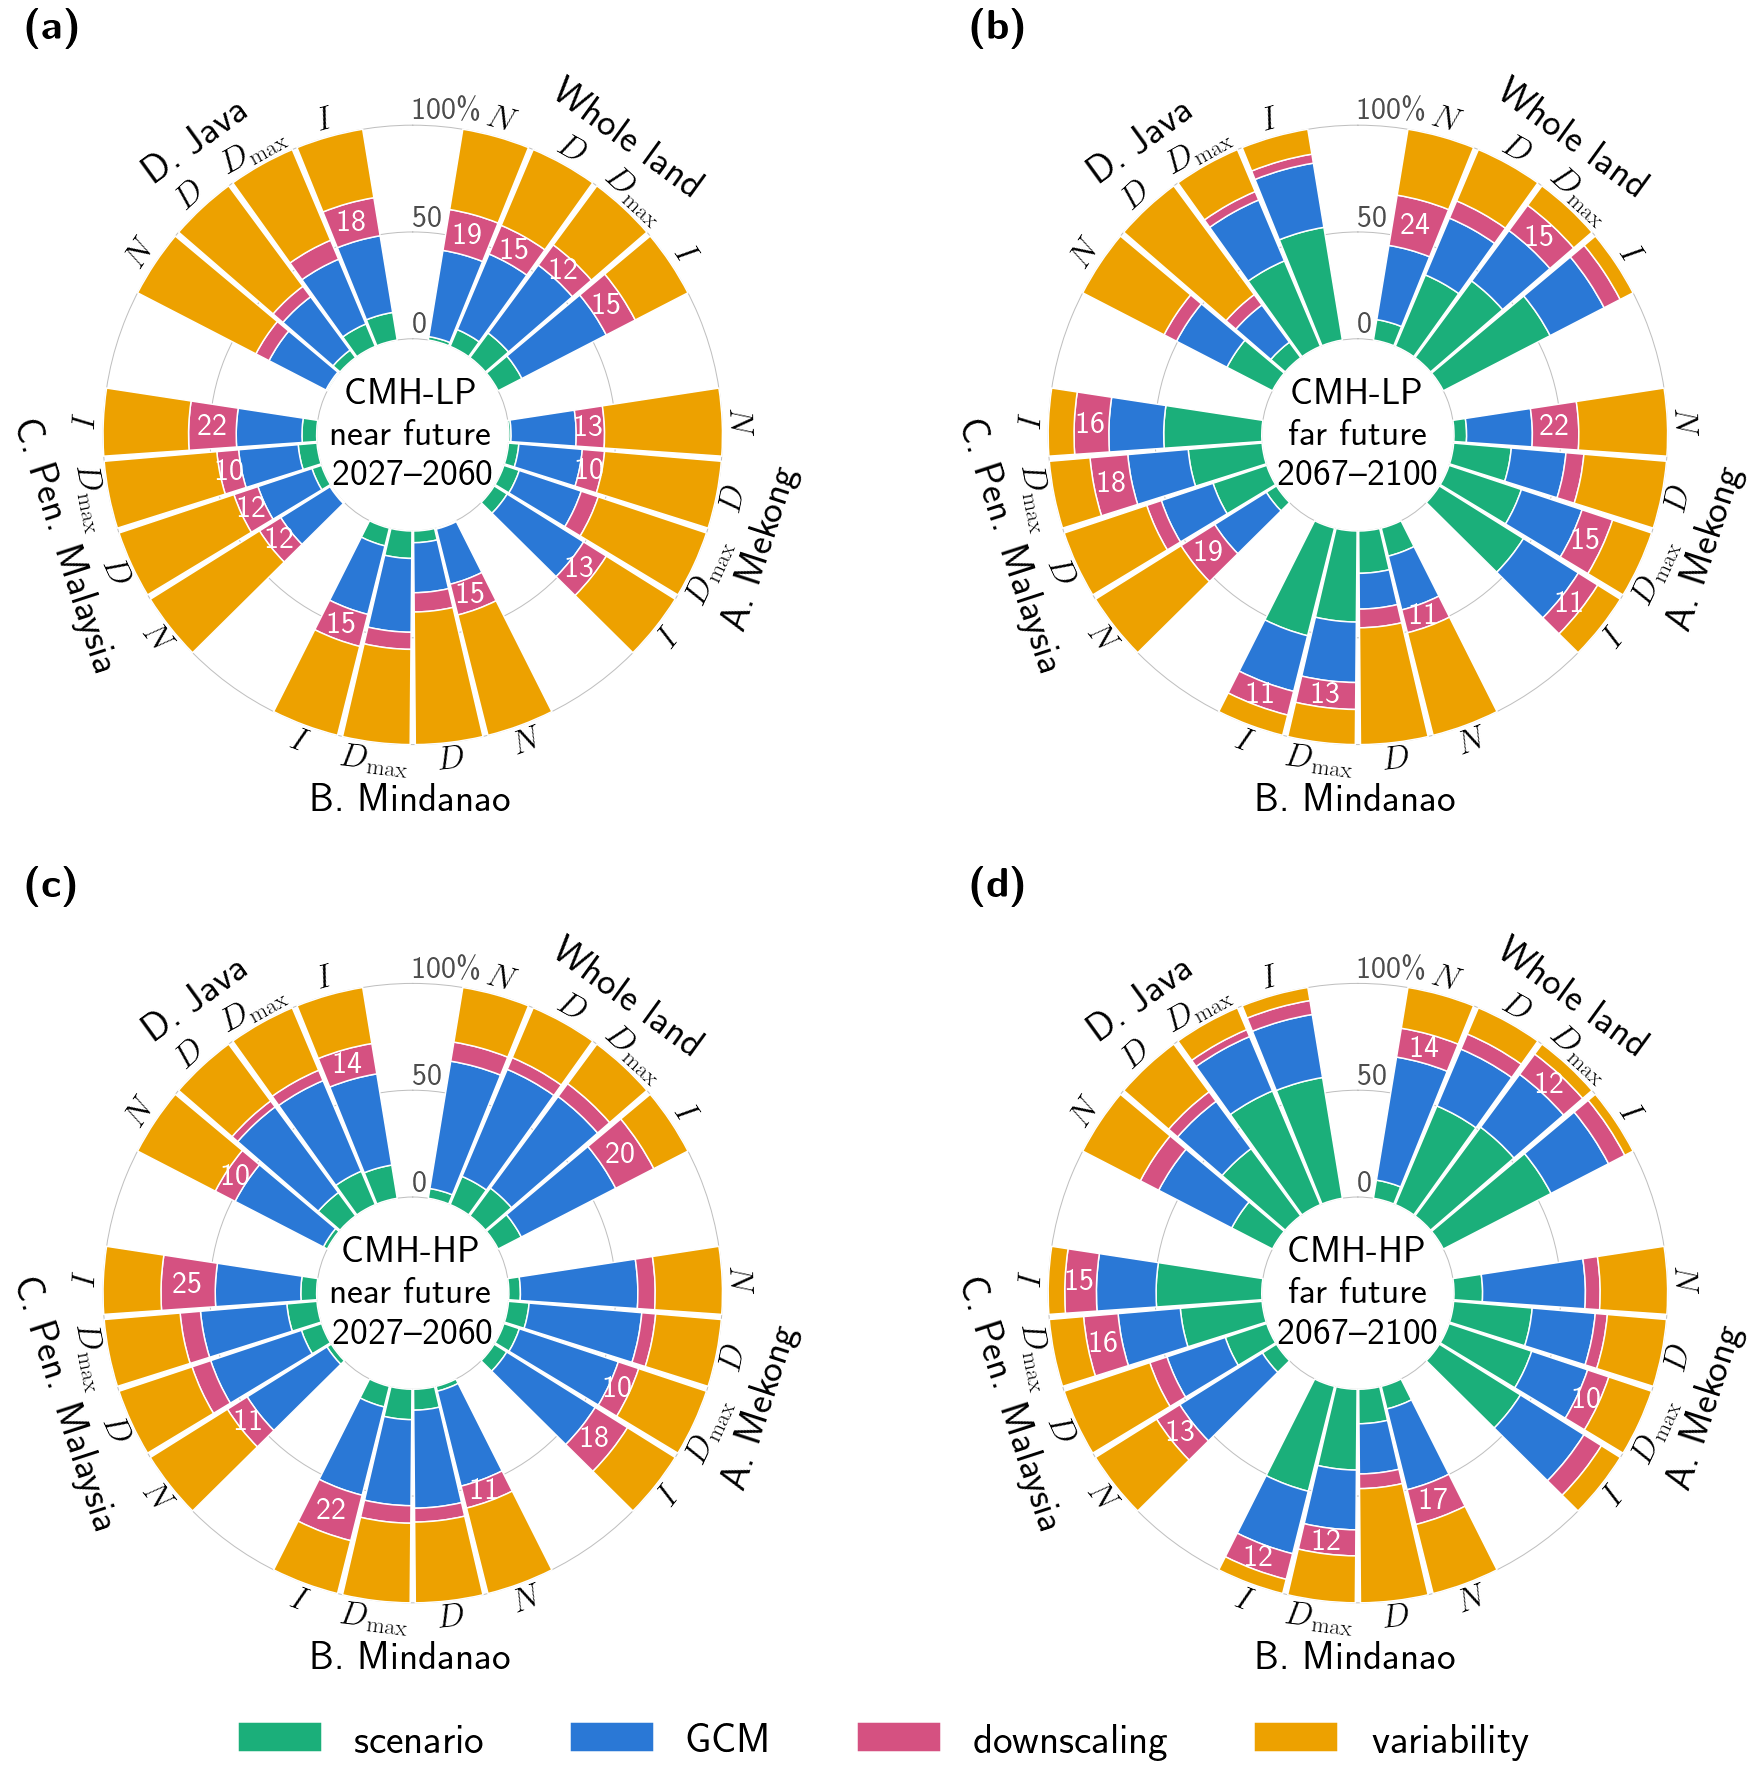

done in 10.9 s
[   12.7 s] TOTAL


In [3]:
assert 'PRS' in globals() and len(PRS) > 1, 'Run the Fig 5 (or Fig 6) cell first: it builds PRS'
import os, time, itertools, numpy as np, matplotlib.pyplot as plt
T0 = time.time(); tk = lambda s_: print(f'[{time.time()-T0:7.1f} s] {s_}', flush=True)
# ---------------- CONFIG (same as the partition cell) ----------------
DS, SSPS, CLS, VARS = ['DBCCA', 'ISIMIP3BASD', 'SRDRN-QDM'], ['ssp126', 'ssp245', 'ssp370', 'ssp585'], ['light', 'heavy'], ['HWN', 'HWF', 'HWD', 'HWI']
MODS = ['ACCESS-CM2','ACCESS-ESM1-5','CMCC-CM2-SR5','CMCC-ESM2','CanESM5','EC-Earth3','EC-Earth3-Veg','FGOALS-g3','GFDL-ESM4','INM-CM5-0','IPSL-CM6A-LR','KACE-1-0-G','MIROC6','MPI-ESM1-2-HR','MRI-ESM2-0','NorESM2-MM','TaiESM1']
REGS = ['Whole land', 'A Mekong', 'B Mindanao', 'C Pen. Malaysia', 'D Java']; RLAB = {r: (r if r == 'Whole land' else r.split()[0] + '. ' + ' '.join(r.split()[1:])) for r in REGS}
Y0, REF, YF, YMAX, HOR = 1981, 2014, 2015, 2100, {'near': (2027, 2060), 'far': (2067, 2100)}
DEG, WIN, DDOF, WEIGHTED, ANOM, EDGE = 4, 11, 0, True, False, True
FRAC = 'ratio_of_means'                      # 'ratio_of_means': mean U_k / mean U over the period (numbers in the paper) | 'mean_of_ratios': mean of U_k(t)/U(t) (Eq. frac as written)
SAVE_FIG, FNAME, SAVE_DIR, FS, NUM_MIN, USETEX = False, 'Fig07_uncertainty_partition', r"D:/G_data/paper-SRDRN/fig-ver3methods", 40, 10, True
SRC, SCW = ['scenario', 'GCM', 'downscaling', 'variability'], ['#1BAF7A', '#2A78D6', '#D55181', '#EDA100']
VLAB, CLAB = {'HWN': '$N$', 'HWF': '$D$', 'HWD': r'$D_{\max}$', 'HWI': '$I$'}, {'light': 'CMH-LP', 'heavy': 'CMH-HP'}
if USETEX:
    try: plt.rcParams['text.usetex'] = True; _f = plt.figure(); _f.text(.5, .5, r'$T_{w,x}$'); _f.canvas.draw(); plt.close(_f)
    except Exception: USETEX = False; plt.close('all')
# ---------------- cube X[method, model, scenario, year], forced response F (4th-order polynomial) ----------------
t_ = time.time(); print(f'[{t_-T0:7.1f} s] computing partition ...', end=' ', flush=True)
T = np.arange(YF, YMAX + 1); xs = (T - T.mean())/T.std(); h = WIN//2; swv = np.lib.stride_tricks.sliding_window_view
use = lambda k: k in PRS and np.asarray(PRS[k]['years']).max() >= YMAX - 5
VOK = [v for v in VARS if any(use(k) and (f'{v}_light', 'Whole land') in PRS[k] for k in itertools.product(DS, MODS, SSPS))]
def cube(v, c, r):
    X = np.full((len(DS), len(MODS), len(SSPS), T.size), np.nan)
    for (i, p), (j, m), (k, s_) in itertools.product(enumerate(DS), enumerate(MODS), enumerate(SSPS)):
        key = (p, m, s_)
        if not use(key) or (f'{v}_{c}', r) not in PRS[key]: continue
        y = np.asarray(PRS[key]['years']).astype(int); x = np.asarray(PRS[key][(f'{v}_{c}', r)], 'f8'); ok = (y >= YF) & (y <= YMAX)
        X[i, j, k, y[ok] - YF] = x[ok] - (np.nanmean(x[(y >= Y0) & (y <= REF)]) if ANOM else 0.)
    F = np.full_like(X, np.nan)
    for ix in np.ndindex(X.shape[:3]):
        g = np.isfinite(X[ix])
        if g.sum() > 3*DEG: F[ix][g] = np.polyval(np.polyfit(xs[g], X[ix][g], DEG), xs[g])
    return X, F
def wmean(v, n): w = np.where(n > 1, n if WEIGHTED else 1., 0.)*np.isfinite(v); return np.sum(np.where(w > 0, v, 0.)*w, (0, 1))/np.maximum(w.sum((0, 1)), 1e-12)
def part(X, F):                                                                  # U[source, year]: scenario, GCM, downscaling, variability
    rv = np.nanvar(swv(np.pad(X - F, [(0, 0)]*3 + [(h, h)], constant_values=np.nan), WIN, axis=-1), -1) if EDGE else np.pad(swv(X - F, WIN, axis=-1).var(-1), [(0, 0)]*3 + [(h, h)], constant_values=np.nan)
    return np.array([np.nanvar(np.nanmean(F, (0, 1)), 0, ddof=DDOF), wmean(np.nanvar(F, 1, ddof=DDOF), np.isfinite(X).sum(1).astype(float)),
                     wmean(np.nanvar(F, 0, ddof=DDOF), np.isfinite(X).sum(0).astype(float)), np.nanmean(rv, (0, 1, 2))])
def share(u, a, b):
    m = (T >= a) & (T <= b) & np.isfinite(u).all(0)
    if FRAC == 'mean_of_ratios': return 100*np.mean(u[:, m]/u[:, m].sum(0), 1)
    d = u[:, m].mean(1); return 100*d/d.sum()
U = {(v, c, r): part(*cube(v, c, r)) for v in VOK for c in CLS for r in REGS}; HK = list(HOR); nh, nv = len(HK), len(VOK)
P = {(v, c, r, k): share(U[(v, c, r)], *HOR[k]) for v in VOK for c in CLS for r in REGS for k in HK}
print(f'done in {time.time()-t_:.1f} s', flush=True)
dsh = np.array([P[q][2] for q in P]); print(f'downscaling share: {dsh.min():.0f}-{dsh.max():.0f} %, median {np.median(dsh):.0f} % | scenario share near future max {max(P[q][0] for q in P if q[3] == "near"):.0f} %')
# ---------------- WHEEL: rows = classes, cols = periods | sectors = regions, wedges = indices, rings = sources | white number = downscaling share ----------------
t_ = time.time(); print(f'[{t_-T0:7.1f} s] drawing {FNAME} ...', end=' ', flush=True)
plt.rcParams.update({'text.usetex': USETEX, 'font.size': FS, 'axes.titlesize': FS, 'axes.labelsize': FS, 'xtick.labelsize': FS-4, 'ytick.labelsize': FS-4, 'legend.fontsize': FS})
bf = (lambda s_: r'\textbf{' + s_ + '}') if USETEX else (lambda s_: s_); PCT_, DASH = (r'\%', '--') if USETEX else ('%', '-'); LET = 'abcdefghijklmnopqrstuvwxyz'
R0, GAP = 45., 1.3; dth = 2*np.pi/(len(REGS)*(nv + GAP)); th = lambda j, q: (j*(nv + GAP) + GAP/2 + q + .5)*dth; rot = lambda t: -np.degrees(t) if (np.degrees(t) < 90 or np.degrees(t) > 270) else 180 - np.degrees(t)
fig, AX = plt.subplots(len(CLS), nh, figsize=(13.5*nh, 13*len(CLS)), subplot_kw=dict(projection='polar'), squeeze=False)
for (i, c), (k, hk) in itertools.product(enumerate(CLS), enumerate(HK)):
    a = AX[i, k]; a.set_theta_zero_location('N'); a.set_theta_direction(-1); a.set_ylim(0, R0 + 136); a.spines['polar'].set_visible(False); a.set_xticks([])
    a.set_yticks([R0, R0 + 50, R0 + 100]); a.set_yticklabels(['0', '50', f'100{PCT_}'], fontsize=FS-8, color='0.3'); a.set_rlabel_position(0); a.grid(axis='y', color='0.75', lw=1); a.set_axisbelow(True)
    for (j, r), (q, v) in itertools.product(enumerate(REGS), enumerate(VOK)):
        p = P[(v, c, r, hk)]; b = R0 + np.concatenate([[0.], np.cumsum(p)])
        for z in range(len(SRC)): a.bar(th(j, q), p[z], width=.93*dth, bottom=b[z], color=SCW[z], ec='w', lw=1.5, label=SRC[z] if j + q == 0 else None)
        if p[2] >= NUM_MIN: a.text(th(j, q), b[2] + p[2]/2, f'{p[2]:.0f}', ha='center', va='center', color='w', fontsize=FS-8)
        a.text(th(j, q), R0 + 108, VLAB[v], ha='center', va='center', fontsize=FS-6, rotation=rot(th(j, q)))
    for j, r in enumerate(REGS): t2 = th(j, (nv - 1)/2); a.text(t2, R0 + 126, RLAB[r], ha='center', va='center', fontsize=FS, rotation=rot(t2))
    a.text(0, 0, f'{CLAB[c]}\n{hk} future\n{HOR[hk][0]}{DASH}{HOR[hk][1]}', ha='center', va='center', fontsize=FS-2, linespacing=1.25); a.set_title(bf(f'({LET[i*nh + k]})'), loc='left', pad=-10, fontsize=FS+2)
fig.legend(*AX[0, 0].get_legend_handles_labels(), loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(.5, .02), fontsize=FS+2); fig.tight_layout(rect=(0, .06, 1, 1))
if SAVE_FIG: os.makedirs(SAVE_DIR, exist_ok=True); fig.savefig(os.path.join(SAVE_DIR, f'{FNAME}.pdf'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig); print(f'done in {time.time()-t_:.1f} s', flush=True); tk('TOTAL')